# Exploratory Data Analysis

In [6]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading our data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

## Filter for Data Analyst Roles in Romania

In [13]:
df_DA_RO = df[(df['job_country'] == 'Romania') & (df['job_title_short'] == 'Data Analyst')]

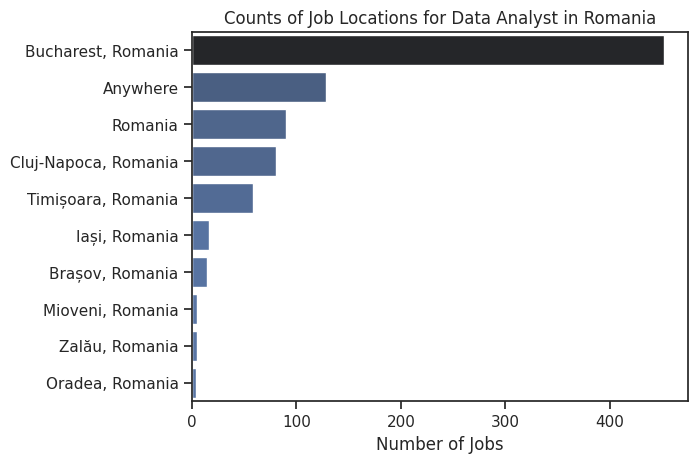

In [24]:
df_plot = df_DA_RO['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_location', hue='count', palette='dark:b_r', legend=False)

plt.title('Counts of Job Locations for Data Analyst in Romania')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

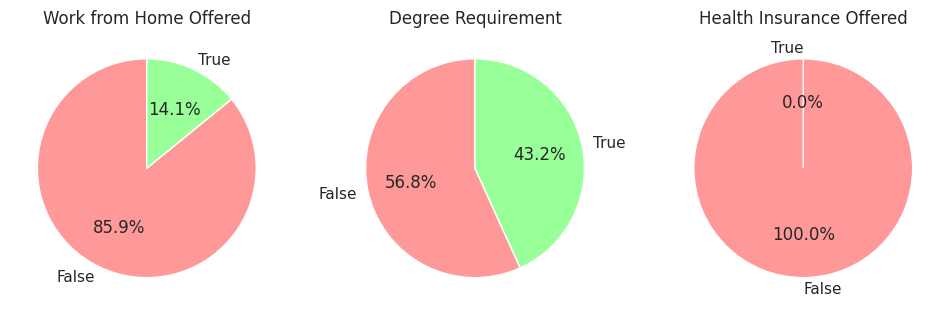

In [30]:
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3)
fig.set_size_inches((12, 5))

slice_colors = ['#ff9999', '#99ff99']

for i, (column, title) in enumerate(dict_column.items()):
  counts = df_DA_RO[column].value_counts().reindex([False, True], fill_value=0)
  ax[i].pie(counts, labels=['False', 'True'], autopct='%1.1f%%', startangle=90, colors=slice_colors)
  ax[i].set_title(title)

plt.show()

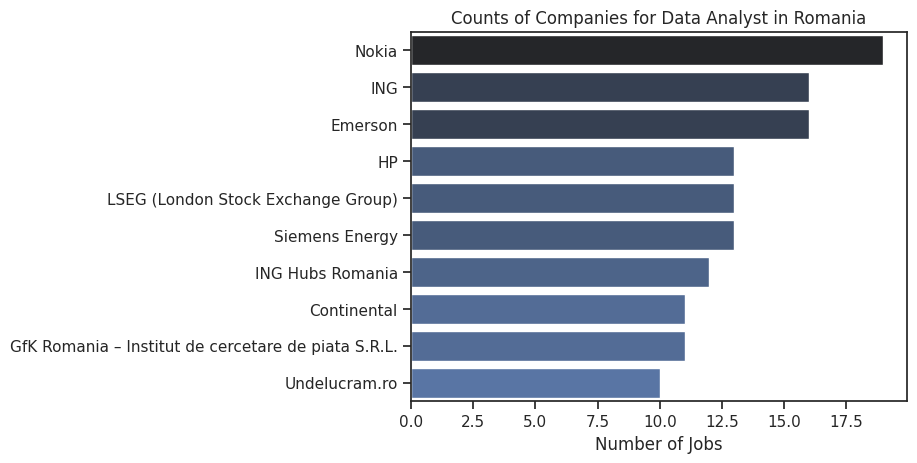

In [31]:
df_plot = df_DA_RO['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend=False)

plt.title('Counts of Companies for Data Analyst in Romania')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()